In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy import stats
import matplotlib.pyplot as plt
import warnings
import os
from collections import defaultdict
from tqdm import tqdm

warnings.filterwarnings('ignore')


path = str(os.getcwd())


In [2]:


NB_ALPHA_DEGENERATE_CUTOFF = 50
VERTEX_BUFFER_FRACTION = 0.20     # vertex must sit in the middle 60% of the range
MIN_COMPARTMENT_FRACTION = 0.05   # flags a brain if any compartment is <5% of its cells
MIN_TOTAL_COUNTS_PER_GENE = 100   # minimum transcript count per gene (across all cells) 
SMOOTH_WINDOW = 41                # rolling-average window (cells), visualization only

# for shading in trend figure: flag positions below/above these percentiles of z_ccf as sparsely sampled
SPARSE_LOW_PCTILE = 2.5           
SPARSE_HIGH_PCTILE = 97.5         

META_COLS = ['cell_label', 'brain_section_label', 'supertype', 'subclass',
             'brain', 'EC', 'x_ccf', 'y_ccf', 'z_ccf']

CATEGORY_COLORS = {
    'medial-enriched':  '#b2182b',
    'lateral-enriched': '#2166ac',
    'middle-peak':       '#1a9850',
    'middle-trough':     '#762a83',
}


# Load and organise data

In [3]:
merfish_full = pd.read_csv(f"{path}/input_data/merfish_final_obj_mesh_filter.csv", index_col=0)
gene_cols = [c for c in merfish_full.columns if c not in META_COLS]

composition = pd.crosstab(merfish_full['brain'], merfish_full['EC']) # count number of cell per region per brain
composition_frac = composition.div(composition.sum(axis=1), axis=0) # what fraction of all brain's cells a subregion is composed of

print(f"Subregion cell fraction per brain:\n{composition_frac}")


Subregion cell fraction per brain:
EC                  LEC       MEC     intEC
brain                                      
Zhuang-ABCA-1  0.282374  0.237410  0.480216
Zhuang-ABCA-2  0.274678  0.206009  0.519313
Zhuang-ABCA-3  0.185714  0.235714  0.578571
Zhuang-ABCA-4  0.000000  0.009709  0.990291


In [4]:
brains_to_exclude = [b for b in composition_frac.index if composition_frac.loc[b].min() < MIN_COMPARTMENT_FRACTION]
merfish = merfish_full[~merfish_full['brain'].isin(brains_to_exclude)].copy()
remaining_brains = sorted(merfish['brain'].unique())

print(f"Brains excluded due to poor subregion representation: {brains_to_exclude}")
print(f"Using {len(merfish)} cells from {sorted(merfish['brain'].unique())}")


Brains excluded due to poor subregion representation: ['Zhuang-ABCA-4']
Using 1209 cells from ['Zhuang-ABCA-1', 'Zhuang-ABCA-2', 'Zhuang-ABCA-3']


In [5]:

bulk = pd.read_csv(f'{path}/output_data/bulk_gene_classes.csv') # bulk sequencing
id2name = dict(zip(bulk['gene_id'], bulk['gene_name']))
id2label = dict(zip(bulk['gene_id'], bulk['category']))


# Prep the variables for the models

In [6]:

gene_total_counts_before_filter = merfish[gene_cols].sum(axis=0)

# Exclude genes below the minimum expression threshold before any model fitting.
genes_below_min_count = gene_total_counts_before_filter[gene_total_counts_before_filter < MIN_TOTAL_COUNTS_PER_GENE].index.tolist()
gene_cols = [g for g in gene_cols if g not in genes_below_min_count]
print(f"Excluding {len(genes_below_min_count)} of {len(gene_total_counts_before_filter)} genes "
      f"with total transcript count < {MIN_TOTAL_COUNTS_PER_GENE}. Proceeding with {len(gene_cols)} genes.")

log_offset = np.log(merfish[gene_cols].sum(axis=1)).values

# smaller mediolateral z-score values are more lateral; 
z_coord = merfish['z_ccf'].values
z_coord_scaled = (z_coord - z_coord.mean()) / z_coord.std()
z_coord_scaled_squared = z_coord_scaled ** 2


# Prep shared variables for the pooled (all-remaining-brains) model
total_transcript_count_per_cell = merfish[gene_cols].sum(axis=1)
log_total_transcript_count_offset = np.log(total_transcript_count_per_cell).values

# prep the intermediate mediolateral axis window for vertex position
z_coord_min, z_coord_max = z_coord.min(), z_coord.max()
z_coord_range = z_coord_max - z_coord_min
vertex_window_lo = z_coord_min + VERTEX_BUFFER_FRACTION * z_coord_range
vertex_window_hi = z_coord_max - VERTEX_BUFFER_FRACTION * z_coord_range

brain_dummies = pd.get_dummies(merfish['brain'], drop_first=True).astype(float)
design_matrix_linear = sm.add_constant(np.column_stack([z_coord_scaled, brain_dummies.values]))
design_matrix_quadratic = sm.add_constant(np.column_stack([z_coord_scaled, z_coord_scaled_squared, brain_dummies.values]))


def fit_poisson_glm(transcript_count, design_matrix, offset):
    return sm.GLM(transcript_count, design_matrix, family=sm.families.Poisson(), offset=offset).fit(cov_type='HC1')

def fit_negative_binomial_glm(transcript_count, design_matrix, offset):
    return sm.NegativeBinomial(transcript_count, design_matrix, offset=offset).fit(disp=0, maxiter=200)


def fit_with_nb_fallback(gene_cols, design_matrix, coef_names):
    """
    Fits Poisson then Negative-Binomial GLMs per gene against `design_matrix`,
    picking NB's coefficient/p-value for each gene unless its alpha is
    degenerate (falls back to Poisson). `coef_names` maps each non-intercept
    coefficient's column index in `design_matrix` (e.g. 1, 2, ...) to a label,
    producing 'coef_<category>_final' / 'p_<category>_final' / 'padj_<category>_final'
    columns per label, plus 'model_used'.
    """
    poisson_records = []
    for gene in tqdm(gene_cols):
        transcript_count = merfish[gene].values.astype(float)
        record = {'gene_id': gene}
        try:
            model = fit_poisson_glm(transcript_count, design_matrix, log_total_transcript_count_offset)
            for idx, name in coef_names.items():
                record[f'coef_{name}_poisson'] = model.params[idx]
                record[f'p_{name}_poisson'] = model.pvalues[idx]
        except Exception:
            for name in coef_names.values():
                record[f'coef_{name}_poisson'] = np.nan
                record[f'p_{name}_poisson'] = np.nan
        poisson_records.append(record)

    nb_records = []
    for gene in tqdm(gene_cols):
        transcript_count = merfish[gene].values.astype(float)
        record = {'gene_id': gene, 'alpha_NB': np.nan}
        try:
            model = fit_negative_binomial_glm(transcript_count, design_matrix, log_total_transcript_count_offset)
            record['alpha_NB'] = model.params[-1]
            for idx, name in coef_names.items():
                record[f'coef_{name}_NB'] = model.params[idx]
                record[f'p_{name}_NB'] = model.pvalues[idx]
        except Exception:
            for name in coef_names.values():
                record[f'coef_{name}_NB'] = np.nan
                record[f'p_{name}_NB'] = np.nan
        nb_records.append(record)

    results = pd.DataFrame(poisson_records).merge(pd.DataFrame(nb_records), on='gene_id')
    nb_usable = results['alpha_NB'].notna() & results[f'p_{name}_NB'].notna() & (results['alpha_NB'] < NB_ALPHA_DEGENERATE_CUTOFF)
    results['model_used'] = np.where(nb_usable, 'NB', 'Poisson_fallback')
    for name in coef_names.values():
        results[f'coef_{name}_final'] = np.where(nb_usable, results[f'coef_{name}_NB'], results[f'coef_{name}_poisson'])
        results[f'p_{name}_final'] = np.where(nb_usable, results[f'p_{name}_NB'], results[f'p_{name}_poisson'])
        results[f'padj_{name}_final'] = multipletests(results[f'p_{name}_final'], method='fdr_bh')[1]
    return results


Excluding 594 of 1122 genes with total transcript count < 100. Proceeding with 528 genes.


# Linear model application

In [7]:
linear_gradient_results = fit_with_nb_fallback(gene_cols, design_matrix_linear, {1: 'linear'})
linear_gradient_results

100%|██████████| 528/528 [00:02<00:00, 245.14it/s]


,gene_id,coef_linear_poisson,p_linear_poisson,alpha_NB,coef_linear_NB,p_linear_NB,model_used,coef_linear_final,p_linear_final,padj_linear_final
0,ENSMUSG00000024798,0.448736,2.153122e-13,1.505783,0.463630,1.271735e-11,NB,0.463630,1.271735e-11,4.567865e-11
1,ENSMUSG00000028780,-0.235662,3.379338e-05,1.972764,-0.275351,2.450637e-04,NB,-0.275351,2.450637e-04,5.196531e-04
2,ENSMUSG00000015843,-0.298616,2.107994e-09,0.772410,-0.331093,9.954678e-09,NB,-0.331093,9.954678e-09,3.055855e-08
3,ENSMUSG00000026768,0.266198,1.794900e-08,0.335442,0.268445,8.538129e-08,NB,0.268445,8.538129e-08,2.423727e-07
4,ENSMUSG00000041046,0.002932,9.599560e-01,1.395790,-0.015906,8.267992e-01,NB,-0.015906,8.267992e-01,8.644554e-01
...,...,...,...,...,...,...,...,...,...,...
523,ENSMUSG00000024064,0.077366,4.116614e-03,0.419670,0.081945,5.370289e-03,NB,0.081945,5.370289e-03,9.547180e-03
524,ENSMUSG00000022324,-0.028120,7.447148e-01,1.332758,-0.025982,8.040703e-01,NB,-0.025982,8.040703e-01,8.490983e-01
525,ENSMUSG00000070047,-0.227361,1.887876e-02,1.254615,-0.217405,7.394569e-03,NB,-0.217405,7.394569e-03,1.280109e-02
526,ENSMUSG00000036111,-0.192178,1.516360e-02,0.748874,-0.197657,1.073105e-02,NB,-0.197657,1.073105e-02,1.790881e-02


# Curved model application

In [8]:
quadratic_curvature_results = fit_with_nb_fallback(gene_cols, design_matrix_quadratic, {1: 'linear', 2: 'quad'})

quadratic_curvature_results['vertex_z_scaled'] = -quadratic_curvature_results['coef_linear_final'] / (2 * quadratic_curvature_results['coef_quad_final'])
quadratic_curvature_results['vertex_z_ccf'] = quadratic_curvature_results['vertex_z_scaled'] * z_coord.std() + z_coord.mean()
quadratic_curvature_results['vertex_in_range'] = quadratic_curvature_results['vertex_z_ccf'].between(vertex_window_lo, vertex_window_hi)
quadratic_curvature_results['shape'] = np.where(quadratic_curvature_results['coef_quad_final'] < 0, 'peak', 'trough')
print("Curvature model (Poisson + NB confirmation) done.")


100%|██████████| 528/528 [00:02<00:00, 220.85it/s]

Curvature model (Poisson + NB confirmation) done.


In [9]:
quadratic_curvature_results

,gene_id,coef_linear_poisson,p_linear_poisson,coef_quad_poisson,p_quad_poisson,alpha_NB,coef_linear_NB,p_linear_NB,coef_quad_NB,p_quad_NB,...,coef_linear_final,p_linear_final,padj_linear_final,coef_quad_final,p_quad_final,padj_quad_final,vertex_z_scaled,vertex_z_ccf,vertex_in_range,shape
0,ENSMUSG00000024798,0.557838,1.872364e-08,-0.130601,0.082475,1.466902,0.540028,4.771641e-10,-0.110218,0.130728,...,0.540028,4.771641e-10,1.983800e-09,-0.110218,0.130728,0.192805,2.449810,2746.197908,False,peak
1,ENSMUSG00000028780,-0.221260,3.761083e-03,-0.266884,0.000312,1.882663,-0.195403,1.520014e-02,-0.277252,0.000234,...,-0.195403,1.520014e-02,2.729821e-02,-0.277252,0.000234,0.000719,-0.352392,1672.461000,True,peak
2,ENSMUSG00000015843,-0.306925,5.948782e-06,-0.269808,0.000348,0.714077,-0.311035,6.894038e-07,-0.276359,0.000002,...,-0.311035,6.894038e-07,2.289341e-06,-0.276359,0.000002,0.000007,-0.562737,1591.861779,True,peak
3,ENSMUSG00000026768,0.324394,1.502301e-07,-0.084264,0.092603,0.325938,0.323806,2.239709e-07,-0.082081,0.115516,...,0.323806,2.239709e-07,7.580552e-07,-0.082081,0.115516,0.172783,1.972490,2563.300599,False,peak
4,ENSMUSG00000041046,0.115365,2.181621e-01,-0.335467,0.000704,1.258102,0.099278,2.309525e-01,-0.331054,0.000017,...,0.099278,2.309525e-01,3.071611e-01,-0.331054,0.000017,0.000063,0.149942,1864.943434,True,peak
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
523,ENSMUSG00000024064,0.147187,3.199534e-05,-0.144755,0.000003,0.397520,0.158030,1.879768e-06,-0.138770,0.000001,...,0.158030,1.879768e-06,5.804195e-06,-0.138770,0.000001,0.000005,0.569394,2025.667542,True,peak
524,ENSMUSG00000022324,0.051128,6.795021e-01,-0.235295,0.068271,1.269523,0.050884,6.730676e-01,-0.231885,0.035024,...,0.050884,6.730676e-01,7.373023e-01,-0.231885,0.035024,0.062686,0.109719,1849.530934,True,peak
525,ENSMUSG00000070047,-0.243113,3.287987e-03,0.106101,0.127401,1.242679,-0.250593,1.964844e-03,0.117065,0.101848,...,-0.250593,1.964844e-03,4.149751e-03,0.117065,0.101848,0.154528,1.070319,2217.609851,True,trough
526,ENSMUSG00000036111,-0.188336,2.212839e-02,-0.023025,0.763207,0.746976,-0.192970,1.536151e-02,-0.021987,0.758919,...,-0.192970,1.536151e-02,2.749449e-02,-0.021987,0.758919,0.807882,-4.388210,126.032061,False,peak


# Brain consistency check
The pooled model above answers "does position predict expression, across all cells from all brains combined?" But a pooled result can in principle be driven mostly by one animal, especially since brains contribute different numbers of cells (so a big brain has more say in the pooled estimate than a small one).

Here we fit each brain separetly (position only, no pooling) and just ask: does this individual brain's data point in the same direction as the pooled result? We do this for both the linear direction (medial vs lateral) and, for curved genes, the shape (peak vs trough). The output is "how many of the brains agree". As a rule of thumb: if at least 2 of the analysed brains agree with the pooled direction, that's reasonable support that the effect isn't just an artifact of one animal.

In [10]:
per_brain_coefficients = {'linear': defaultdict(dict), 'quadratic': defaultdict(dict)}

# apply quadratic and linear models
for brain_id in tqdm(remaining_brains):
    brain_subset = merfish[merfish['brain'] == brain_id]
    z_scaled = (brain_subset['z_ccf'].values - brain_subset['z_ccf'].mean()) / brain_subset['z_ccf'].std()
    log_offset = np.log(brain_subset[gene_cols].sum(axis=1)).values
    design_matrices = {
        'linear': sm.add_constant(z_scaled),
        'quadratic': sm.add_constant(np.column_stack([z_scaled, z_scaled ** 2])),
    }

    for gene in tqdm(gene_cols):
        transcript_count = brain_subset[gene].values.astype(float)
        for model, design_matrix in design_matrices.items():
            try:
                coef = fit_poisson_glm(transcript_count, design_matrix, log_offset).params[-1]
            except Exception:
                coef = np.nan
            per_brain_coefficients[model][gene][brain_id] = coef

# For each gene, count how many brains agree in sign with the pooled estimate
def add_concordance_columns(results_df, coef_col, per_brain_coefficients):
    def concordance(gene, coef):
        signs = [np.sign(v) for v in per_brain_coefficients.get(gene, {}).values() if not np.isnan(v)]
        return signs.count(np.sign(coef)), len(signs)

    results_df[['n_brains_concordant', 'n_brains_tested']] = [
        concordance(gene, coef) for gene, coef in zip(results_df['gene_id'], results_df[coef_col])
    ]

add_concordance_columns(linear_gradient_results, 'coef_linear_final', per_brain_coefficients['linear'])
add_concordance_columns(quadratic_curvature_results, 'coef_quad_final', per_brain_coefficients['quadratic'])

# results of the check
for label, results_df, padj_col in [
    ('linear-gradient', linear_gradient_results, 'padj_linear_final'),
    ('curved-gradient', quadratic_curvature_results, 'padj_quad_final'),
]:
    concordant_fraction = (results_df.loc[results_df[padj_col] < 0.05, 'n_brains_concordant'] >= 2).mean() * 100
    print(f"(Of significant {label} genes, {concordant_fraction:.0f}% "
          f"have at least 2/{len(remaining_brains)} brains agreeing in direction)")


100%|██████████| 3/3 [00:01<00:00,  1.89it/s]

(Of significant linear-gradient genes, 99% have at least 2/3 brains agreeing in direction)
(Of significant curved-gradient genes, 99% have at least 2/3 brains agreeing in direction)


# Gene pattern categories
Every gene gets exactly one label:
- medial-enriched   -> significant straight-line increase toward MEC
- lateral-enriched  -> significant straight-line increase toward LEC
- middle-peak       -> significant genuine peak in the intermediate zone
- middle-trough     -> significant genuine dip in the intermediate zone
- none              -> no significant pattern

If a gene shows both a significant linear trend and a significant curvature, we pick whichever effect is larger (comparing the two standardized coefficients) to decide the label: a gene can have a small amount of statistically-detectable curvature riding on top of overwhelmingly straight gradient (or vice versa); the label should reflect whichever pattern actually dominates the gene's expression.

In [11]:

gene_category_results = linear_gradient_results[['gene_id', 'coef_linear_final', 'padj_linear_final',
              'n_brains_concordant', 'n_brains_tested', 'model_used']].merge(
    quadratic_curvature_results[['gene_id', 'coef_quad_final', 'padj_quad_final', 'vertex_z_ccf',
          'vertex_in_range', 'shape', 'n_brains_concordant', 'n_brains_tested']],
    on='gene_id', suffixes=('_lin', '_quad'))

linear_is_significant = gene_category_results['padj_linear_final'] < 0.05
curvature_is_significant = (gene_category_results['padj_quad_final'] < 0.05) & gene_category_results['vertex_in_range']

# when both tests are significant, let the larger standardized effect size
linear_effect_dominant = gene_category_results['coef_linear_final'].abs() >= gene_category_results['coef_quad_final'].abs()

gene_category_results['category'] = np.select(
    [
        curvature_is_significant & linear_is_significant & linear_effect_dominant & (gene_category_results['coef_linear_final'] > 0),
        curvature_is_significant & linear_is_significant & linear_effect_dominant & (gene_category_results['coef_linear_final'] < 0),
        curvature_is_significant & linear_is_significant & ~linear_effect_dominant & (gene_category_results['shape'] == 'peak'),
        curvature_is_significant & linear_is_significant & ~linear_effect_dominant & (gene_category_results['shape'] == 'trough'),
        curvature_is_significant & ~linear_is_significant & (gene_category_results['shape'] == 'peak'),
        curvature_is_significant & ~linear_is_significant & (gene_category_results['shape'] == 'trough'),
        ~curvature_is_significant & linear_is_significant & (gene_category_results['coef_linear_final'] > 0),
        ~curvature_is_significant & linear_is_significant & (gene_category_results['coef_linear_final'] < 0),
    ],
    ['medial-enriched', 'lateral-enriched', 'middle-peak', 'middle-trough',
     'middle-peak', 'middle-trough', 'medial-enriched', 'lateral-enriched'],
    default='none'
)

# for the "middle" categories, the relevant brain-consistency count is the
# curvature one; for the pole categories, it's the linear one
gene_category_results['n_brains_concordant_relevant'] = np.where(
    gene_category_results['category'].isin(['middle-peak', 'middle-trough']),
    gene_category_results['n_brains_concordant_quad'], gene_category_results['n_brains_concordant_lin'])
gene_category_results['n_brains_tested_relevant'] = np.where(
    gene_category_results['category'].isin(['middle-peak', 'middle-trough']),
    gene_category_results['n_brains_tested_quad'], gene_category_results['n_brains_tested_lin'])

gene_category_results['gene_name'] = gene_category_results['gene_id'].map(id2name)
gene_category_results['bulk_label'] = gene_category_results['gene_id'].map(id2label).fillna('not_in_bulk')

print(gene_category_results['category'].value_counts())
print(f"\nOf non-'none' genes, breakdown by how many brains agree in direction:")
print(gene_category_results.loc[gene_category_results['category']!='none', 'n_brains_concordant_relevant'].value_counts().sort_index())

final_cols = ['gene_id', 'gene_name', 'category',
              'coef_linear_final', 'padj_linear_final',
              'coef_quad_final', 'padj_quad_final', 'vertex_z_ccf',
              'n_brains_concordant_relevant', 'n_brains_tested_relevant',
              'bulk_label']
gene_category_results[final_cols].to_csv('output_data/merfish_final_gene_categories.csv', index=False)
print("\nSaved main results file: merfish_final_gene_categories.csv")

# full per-model detail tables, for deeper inspection
linear_gradient_results.to_csv('output_data/merfish_linear_gradient_detail.csv', index=False)
quadratic_curvature_results.to_csv('output_data/merfish_quadratic_curvature_detail.csv', index=False)
print("Saved: merfish_linear_gradient_detail.csv (full linear model detail)")
print("Saved: merfish_quadratic_curvature_detail.csv (full curvature model detail)")


category
lateral-enriched    149
medial-enriched     122
none                109
middle-peak         105
middle-trough        43
Name: count, dtype: int64

Of non-'none' genes, breakdown by how many brains agree in direction:
n_brains_concordant_relevant
1      1
2     53
3    365
Name: count, dtype: int64

Saved main results file: merfish_final_gene_categories.csv
Saved: merfish_linear_gradient_detail.csv (full linear model detail)
Saved: merfish_quadratic_curvature_detail.csv (full curvature model detail)


# Concordance with bulk RNAseq classification

In [12]:

bulk_to_merfish = {
    'MEC-enriched': 'medial-enriched',
    'LEC-enriched': 'lateral-enriched',
    'intEC-enriched': 'middle-peak',
    'intEC-suppressed': 'middle-trough',
}

summary_rows = []
for bulk_class, expected_category in bulk_to_merfish.items():
    bulk_class_subset = gene_category_results[gene_category_results['bulk_label'] == bulk_class]
    n_in_panel = len(bulk_class_subset)
    n_agree = (bulk_class_subset['category'] == expected_category).sum()
    n_none = (bulk_class_subset['category'] == 'none').sum()
    n_disagree = n_in_panel - n_agree - n_none
    print(f"\nBulk '{bulk_class}' genes present in MERFISH panel: {n_in_panel}")
    print(f"  Agreed (MERFISH: {expected_category}): {n_agree}")
    print(f"  Not significant in MERFISH: {n_none}")
    print(f"  Disagreed (different category): {n_disagree}")
    summary_rows.append({'bulk_class': bulk_class, 'n_in_panel': n_in_panel,
                          'n_agree': n_agree, 'n_not_significant': n_none,
                          'n_disagree': n_disagree})

pd.DataFrame(summary_rows).to_csv('output_data/merfish_bulk_concordance_summary.csv', index=False)
print("\nSaved: merfish_bulk_concordance_summary.csv")




Bulk 'MEC-enriched' genes present in MERFISH panel: 34
  Agreed (MERFISH: medial-enriched): 25
  Not significant in MERFISH: 4
  Disagreed (different category): 5

Bulk 'LEC-enriched' genes present in MERFISH panel: 23
  Agreed (MERFISH: lateral-enriched): 17
  Not significant in MERFISH: 3
  Disagreed (different category): 3

Bulk 'intEC-enriched' genes present in MERFISH panel: 2
  Agreed (MERFISH: middle-peak): 2
  Not significant in MERFISH: 0
  Disagreed (different category): 0

Bulk 'intEC-suppressed' genes present in MERFISH panel: 5
  Agreed (MERFISH: middle-trough): 1
  Not significant in MERFISH: 1
  Disagreed (different category): 3

Saved: merfish_bulk_concordance_summary.csv


# Trend figure

One panel per category, showing single-cell expression (log-normalized,
z-scored per gene) as a function of continuous mediolateral position (z_ccf). Smoothing uses a centered rolling average over all cells within +/-DISTANCE_HALF_WINDOW z_ccf units of each point, for visual clarity only; All statistical classification above was performed on unsmoothed single-cell data. 

Grey shading marks the mediolateral extremes as a data-density cue.

In [15]:
total_transcript_count_per_cell.median()

np.float64(502.0)

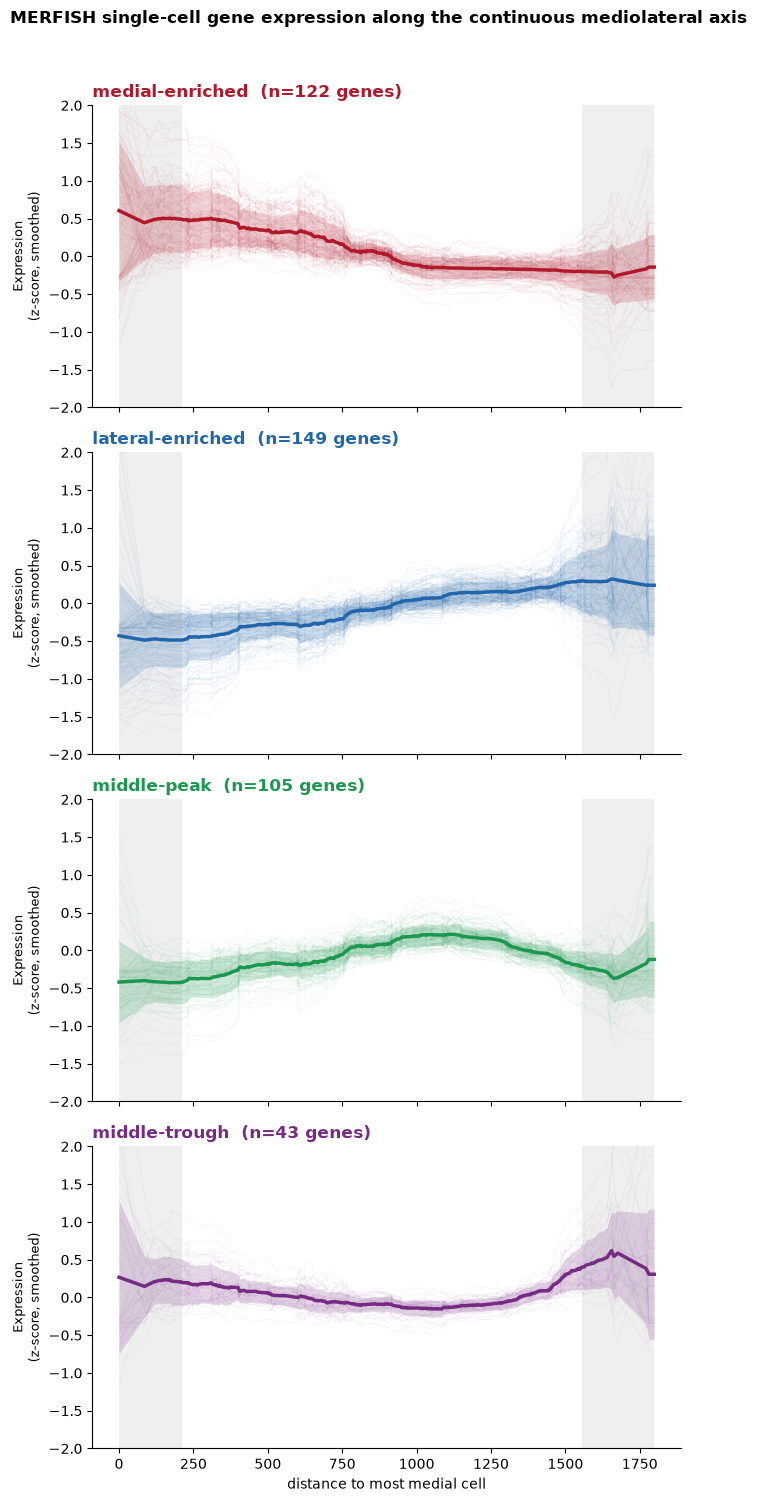

Saved: FIG_merfish_mediolateral_trend.svg

Sparse-sampling shading thresholds: distance to most medial cell < 210.2 or > 1555.0
  (n=31 cells below, n=31 cells above, out of 1209 total)


In [13]:
normalization_factor = total_transcript_count_per_cell.median() / total_transcript_count_per_cell.replace(0, np.nan)
cell_order = merfish['z_ccf'].sort_values(ascending=False).index  # medial (distance 0) -> lateral (increasing distance)
distance_to_medial_ordered = z_coord_max - merfish.loc[cell_order, 'z_ccf'].values

sparse_low = np.percentile(distance_to_medial_ordered, SPARSE_LOW_PCTILE)
sparse_high = np.percentile(distance_to_medial_ordered, SPARSE_HIGH_PCTILE)


def per_gene_zscore(gene_list, cell_order):
    log_normalized_expression = np.log1p(merfish.loc[cell_order, gene_list].multiply(normalization_factor.loc[cell_order], axis=0))
    gene_mean, gene_std = log_normalized_expression.mean(axis=0), log_normalized_expression.std(axis=0) + 1e-9
    return (log_normalized_expression - gene_mean) / gene_std


def rolling_mean_by_distance(position, expression_zscore, half_window=100):
    """
    Centered mean over all rows within +/- half_window distance units of each point.

    """
    position = np.asarray(position)
    lo_idx = np.searchsorted(position, position - half_window, side="left")
    hi_idx = np.searchsorted(position, position + half_window, side="right")

    values = expression_zscore.values
    cumulative_sums = np.vstack([np.zeros((1, values.shape[1])), np.cumsum(values, axis=0)])
    window_sums = cumulative_sums[hi_idx] - cumulative_sums[lo_idx]
    window_counts = (hi_idx - lo_idx)[:, None]
    return pd.DataFrame(window_sums / window_counts, index=expression_zscore.index, columns=expression_zscore.columns)


categories_to_plot = [c for c in CATEGORY_COLORS if c in gene_category_results['category'].unique()]
fig, axes = plt.subplots(len(categories_to_plot), 1,
                          figsize=(7, 3.75 * len(categories_to_plot)), sharex=True)
if len(categories_to_plot) == 1:
    axes = [axes]

for ax, category in zip(axes, categories_to_plot):
    category_genes = gene_category_results.loc[gene_category_results['category'] == category, 'gene_id'].tolist()
    category_color = CATEGORY_COLORS[category]
    if len(category_genes) == 0:
        ax.set_title(f"{category}  (n=0 genes)", fontsize=11)
        continue

    gene_zscore_matrix = per_gene_zscore(category_genes, cell_order)
    gene_zscore_smoothed = rolling_mean_by_distance(distance_to_medial_ordered, gene_zscore_matrix)

    ax.axvspan(distance_to_medial_ordered.min(), sparse_low, color='grey', alpha=0.12, lw=0, zorder=0)
    ax.axvspan(sparse_high, distance_to_medial_ordered.max(), color='grey', alpha=0.12, lw=0, zorder=0)

    for gene_id in category_genes:
        ax.plot(distance_to_medial_ordered, gene_zscore_smoothed[gene_id].values, color=category_color, alpha=0.05, lw=0.6, zorder=1)

    mean_curve = gene_zscore_smoothed.mean(axis=1).values
    sd_curve = gene_zscore_smoothed.std(axis=1).values
    ax.fill_between(distance_to_medial_ordered, mean_curve - sd_curve, mean_curve + sd_curve,
                     color=category_color, alpha=0.18, lw=0, zorder=2)
    ax.plot(distance_to_medial_ordered, mean_curve, color=category_color, lw=2.5, zorder=3)

    ax.set_title(f"{category}  (n={len(category_genes)} genes)", color=category_color, fontsize=12, fontweight='bold', loc='left')
    ax.set_ylabel("Expression\n(z-score, smoothed)", fontsize=9)
    ax.set_ylim(-2, 2)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)

axes[-1].set_xlabel(
    "distance to most medial cell", fontsize=10)

fig.suptitle("MERFISH single-cell gene expression along the continuous mediolateral axis",
             fontsize=12, y=0.998, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig('FIG_merfish_mediolateral_trend.svg', dpi=170, bbox_inches='tight')
plt.show()
plt.close(fig)
print("Saved: FIG_merfish_mediolateral_trend.svg")

print(f"\nSparse-sampling shading thresholds: distance to most medial cell < {sparse_low:.1f} or > {sparse_high:.1f}")
print(f"  (n={int((distance_to_medial_ordered<sparse_low).sum())} cells below, "
      f"n={int((distance_to_medial_ordered>sparse_high).sum())} cells above, out of {len(merfish)} total)")
